In [4]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import time
import random
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import urljoin
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
BASE ="http://books.toscrape.com/"

def get_soup(url):
    response = requests.get(url, headers={"User-Agent":"Mozilla/5.0"}, timeout=20)
    response.raise_for_status()
    return BeautifulSoup(response.text, "html.parser")
books = []
page_url = "https://books.toscrape.com/catalogue/page-1.html"
page_num=1

print("starting scrape... (This takes 15-20 mins, please wait!)")

while page_url:
    print(f" Scraping listing page {page_num}...")
    soup = get_soup(page_url)

    for card in soup.select("article.product_pod"):
        title=card.h3.a["title"]
        price_text = card.select_one("p.price_color").get_text(strip=True)
        rating_word = [c for c in card.select_one("p.star-rating")["class"] if c != "star-rating"][0]
        availability_text=card.select_one("p.instock.availability").get_text("", strip=True)
        href = card.h3.a["href"]
        product_url = urljoin(page_url, href)

        books.append ({
            "title":title,
            "price_text":price_text,
            "rating_word":rating_word,
            "availability_text":availability_text,
            "product_url":product_url

        })

    next_link = soup.select_one("li.next > a")

    if next_link and "page-" in next_link["href"]:
        page_url = urljoin(page_url, next_link["href"])
    else:
        page_url = None

    page_num+=1
    time.sleep(0.5)

df = pd.DataFrame(books)
print(f"\n Scraped {len(df)} book listings.")

df.to_csv("books_raw.csv", index=False)
print("Raw data saved successfully!")

import pandas as pd
df = pd.read_csv("books_raw.csv")
df.head()



starting scrape... (This takes 15-20 mins, please wait!)
 Scraping listing page 1...
 Scraping listing page 2...
 Scraping listing page 3...
 Scraping listing page 4...
 Scraping listing page 5...
 Scraping listing page 6...
 Scraping listing page 7...
 Scraping listing page 8...
 Scraping listing page 9...
 Scraping listing page 10...
 Scraping listing page 11...
 Scraping listing page 12...
 Scraping listing page 13...
 Scraping listing page 14...
 Scraping listing page 15...
 Scraping listing page 16...
 Scraping listing page 17...
 Scraping listing page 18...
 Scraping listing page 19...
 Scraping listing page 20...
 Scraping listing page 21...
 Scraping listing page 22...
 Scraping listing page 23...
 Scraping listing page 24...
 Scraping listing page 25...
 Scraping listing page 26...
 Scraping listing page 27...
 Scraping listing page 28...
 Scraping listing page 29...
 Scraping listing page 30...
 Scraping listing page 31...
 Scraping listing page 32...
 Scraping listing page 3

,title,price_text,rating_word,availability_text,product_url
0,A Light in the Attic,Â£51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...
1,Tipping the Velvet,Â£53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...
2,Soumission,Â£50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...
3,Sharp Objects,Â£47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...


In [6]:
categories, descriptions = [], []

print("Fetching categories and descriptions...")

for i, row in df.iterrows():
    try:
        soup=get_soup(row["product_url"])
        crumbs= soup.select("ul.breadcrumb li a")
        category=crumbs[-1].get_text(strip=True) if len(crumbs) >= 2 else "unknown"

        desc_tag = soup.select_one("#product_description")
        description=""
        if desc_tag and desc_tag.find_next_sibling("p"):
            description=desc_tag.find_next_sibling("p").get_text(strip=True)

        categories.append(category)
        descriptions.append(description)
    except Exception:
        categories.append("unknown")
        descriptions.append("")

    if (i + 1) % 200 ==0:
        print(f" Fetched {i+1} details...")
    time.sleep(0.2)

df["category"]=categories
df["description"]=descriptions
print("Detail scraping complete!")

Fetching categories and descriptions...
 Fetched 200 details...
 Fetched 400 details...
 Fetched 600 details...
 Fetched 800 details...
 Fetched 1000 details...
Detail scraping complete!


In [11]:
print("Cleaning data")

df["price"] = df["price_text"].str.extract(r'([\d.]+)').astype(float)

rating_map = {"One": 1, "Two":2, "Three":3, "Four":4, "Five":5}
df["rating"] = df["rating_word"].map(rating_map)

df["in_stock"] = df["availability_text"].str.contains("In stock", case=False, na=False).astype(int)
df["stock_quantity"] = df["availability_text"].astype(str).str.extract(r"\((\d+) available\)")[0].fillna("0").astype(int)

df["category"] = "unknown"
df["description"] = ""
df["description_word_count"] = 0

df["title_length"]=df["title"].str.len()

df=df.drop_duplicates(subset=["title", "product_url"]).reset_index(drop=True)

df.to_csv("books_clean.csv", index=False)
print(f"Data cleaned. Final shape: {df.shape}")
print("Saved as book_clean.csv")
df.head()

Cleaning data
Data cleaned. Final shape: (1000, 13)
Saved as book_clean.csv


,title,price_text,rating_word,availability_text,product_url,category,description,price,rating,in_stock,stock_quantity,description_word_count,title_length
0,A Light in the Attic,Â£51.77,Three,In stock,https://books.toscrape.com/catalogue/a-light-i...,unknown,,51.77,3,1,0,0,20
1,Tipping the Velvet,Â£53.74,One,In stock,https://books.toscrape.com/catalogue/tipping-t...,unknown,,53.74,1,1,0,0,18
2,Soumission,Â£50.10,One,In stock,https://books.toscrape.com/catalogue/soumissio...,unknown,,50.10,1,1,0,0,10
3,Sharp Objects,Â£47.82,Four,In stock,https://books.toscrape.com/catalogue/sharp-obj...,unknown,,47.82,4,1,0,0,13
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,https://books.toscrape.com/catalogue/sapiens-a...,unknown,,54.23,5,1,0,0,37


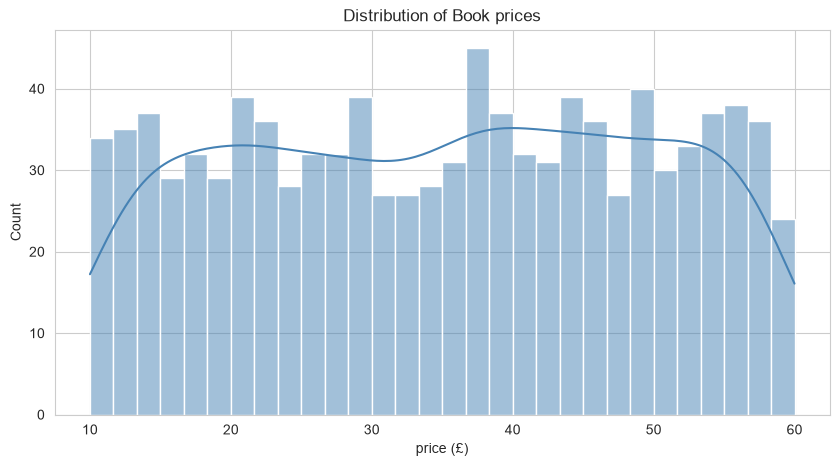

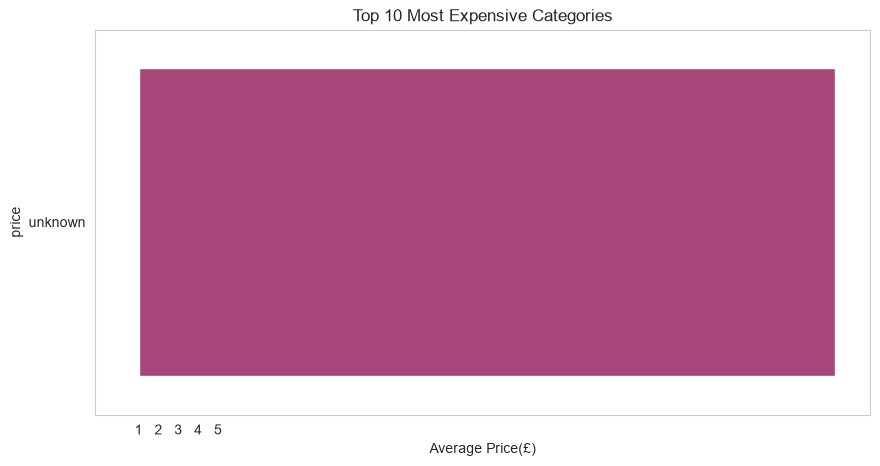

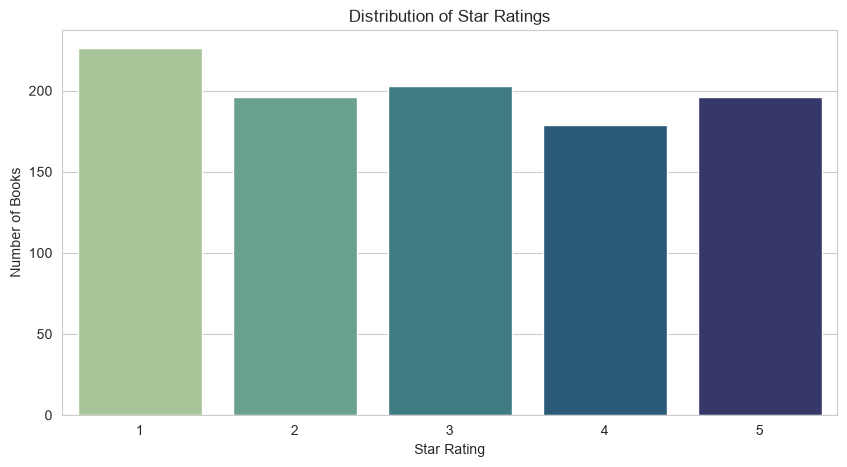

In [8]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"]=(10,5)

sns.histplot(df["price"], bins=30, kde=True, color="steelblue")
plt.title("Distribution of Book prices")
plt.xlabel("price (£)")
plt.show()

sns.boxplot(data=df, x="rating", y="price", hue="rating", palette="viridis", legend=False)

top_cat = df.groupby("category")["price"].mean().sort_values(ascending=False).head(10)
sns.barplot(x=top_cat.values, y=top_cat.index, hue=top_cat.index, palette="magma", legend=False)
plt.title("Top 10 Most Expensive Categories")
plt.xlabel("Average Price(£)")
plt.show()

plt.figure()
sns.countplot(data=df, x="rating", hue="rating", palette="crest", legend=False)
plt.title("Distribution of Star Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Number of Books")
plt.show()

In [9]:
numeric_features = ["rating","in_stock", "stock_quantity", "title_length", "description_word_count"]
categorical_features = ["category"]

X = df[numeric_features + categorical_features]
Y = df["price"]

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"),categorical_features)
])

model= Pipeline([
    ("preprocess", preprocess),
    ("lr", LinearRegression())
])

model.fit(X_train, Y_train)
print("Model trained successfully.")

Model trained successfully.


MAE: £12.71
RMSE: £14.58
R^2:-0.0118


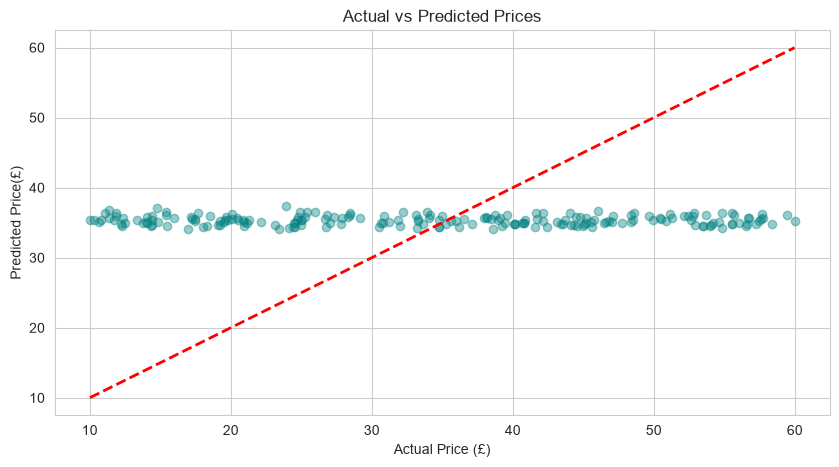

In [10]:
Y_pred = model.predict(X_test)

mae = mean_absolute_error(Y_test, Y_pred)
rmse = np.sqrt(mean_squared_error(Y_test, Y_pred))
r2 = r2_score(Y_test, Y_pred)

print(f"MAE: £{mae:.2f}")
print(f"RMSE: £{rmse:.2f}")
print(f"R^2:{r2:.4f}")

plt.scatter(Y_test, Y_pred, alpha=0.4, color="teal")
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], "r--", lw=2)
plt.xlabel("Actual Price (£)")
plt.ylabel("Predicted Price(£)")
plt.title("Actual vs Predicted Prices")
plt.show()